# UNSW-NB15: Data Information

## Source/Useful Links

Get the data from: https://www.unsw.adfa.edu.au/unsw-canberra-cyber/cybersecurity/ADFA-NB15-Datasets/

Refer: http://dx.doi.org/10.1080/19393555.2015.1125974


This dataset has been created by: Nour Moustafa, IEEE student Member, Jill Slay


## What is IDS (Intrusion Detection System)?

Intrusion Detection Systems (IDS) are precisely present to prevent attacks and infiltration to Networks, which might affect the organization. They monitor network traffic for suspicious activities and issue alert in case of issues.

**Types if IDS:**
> 1. *Signature-based intrusion detection*– In this kind incoming attacks are compared with pre-existing database of known attacks.
> 2. *Anomaly-based intrusion detection*- It uses statistics to form a baseline usage of the networks at different time intervals. They were introduced to detect unknown attacks.

Based on where they discover, they can be classified into:
1. Network intrusion detection (NIDS)
2. Host intrusion detection (HIDS)

## Problem Statement

With the rise of Internet usage, it is very important to protect Networks.  The most common risk to a network’s security is an intrusion such as brute force, denial of service or even an infiltration from within a network. With the changing patterns in network behavior, it is necessary to switch to a dynamic approach to detect and prevent such intrusions.

**Importance of this dataset:**
 
Although there were few daatset available before this dataset for NIDS, but they were generated decades ago and do not provide realistic outputs. That's why this dataset had been created by Nour Moustafa to tackle existing problems like: unbalanced dataset, missing values etc.

## Data Collection

This dataset has 4 CSV files of the data records and each CSV file contains attack and normal records.
<table>
<tr>
<th> file name </th>
<th> file name size</th>
<th> number of records </th>
<th> number of features </th>
</tr>

<tr>
<td> UNSWNB15_1.csv </td>
<td> 161.2 MB </td>
<td> 700000 </td>
<td> 49 </td>
</tr>

<tr>
<td> UNSWNB15_2.csv </td>
<td> 157.6 MB </td>
<td> 700000 </td>
<td> 49 </td>
</tr>

<tr>
<td> UNSWNB15_3.csv </td>
<td> 147.4 MB </td>
<td> 700000 </td>
<td> 49 </td>
</tr>

<tr>
<td> UNSWNB15_4.csv </td>
<td> 91.3 MB </td>
<td> 440044 </td>
<td> 49 </td>
</tr>
</table>


## Features in the Dataset

This dataset has 49 features.
<br>
There are 3 different datatypes:
- Categorical: proto, state, service, attack_cat
- Binary: is_sm_ips_ports, is_ftp_login
- Numerical: Rest of the features

## ML Problem Formulation

*Binary classification of attack category*

The dataset has "label" with 0 and 1 where 0 represents non-attack and 1 represent attack. So with the features available we will try to predict a given datapoint whether it belongs to attack or non-attack category.

## Performance Metrics

1. Accuracy
2. False Alarm Rate

# UNSW-NB15: Data cleaning and preprocessing

## Importing libraries

In [1]:
import numpy as np  # for array
import pandas as pd  # for csv files and dataframe
import matplotlib.pyplot as plt  # for plotting

import pickle  # To load data int disk

import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split


%matplotlib inline

# User-configurable cap across all raw traffic records from the four UNSW-NB15 parts.
MAX_RAW_ROWS = 50_000
RAW_SAMPLE_SEED = 16
MIN_VALID_RAW_ROWS = 10_000
if not isinstance(MAX_RAW_ROWS, int) or isinstance(MAX_RAW_ROWS, bool):
    raise TypeError("MAX_RAW_ROWS must be an integer number of raw records.")
if MAX_RAW_ROWS < MIN_VALID_RAW_ROWS:
    raise ValueError(f"MAX_RAW_ROWS must be at least {MIN_VALID_RAW_ROWS:,} to meet the project minimum.")

getting the data


In [2]:
import kagglehub
from pathlib import Path

data_dir = Path("../data")

required_files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv",
]

if not all((data_dir / filename).exists() for filename in required_files):
    path = kagglehub.dataset_download(
        "mrwellsdavid/unsw-nb15",
        output_dir=str(data_dir),
        force_download=False
    )
    print("Dataset downloaded to:", path)
else:
    print("Dataset already exists. Skipping download.")

Dataset already exists. Skipping download.


## Reading data

In [3]:
# Creating a empty dict, where I will save all parameters required for test data transformation

saved_dict = {}

In [4]:
# Load the feature schema, then take a reproducible uniform reservoir sample across all four traffic files.
# The feature schema and events-list CSV are not traffic records.
import csv
from pathlib import Path
import random

df_col = pd.read_csv('../data/NUSW-NB15_features.csv', encoding='ISO-8859-1')
raw_files = [Path(f'../data/UNSW-NB15_{part}.csv') for part in range(1, 5)]
missing_files = [str(path) for path in raw_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing UNSW-NB15 traffic files: {missing_files}")

rng = random.Random(RAW_SAMPLE_SEED)
sampled_rows = []
valid_raw_rows_seen = 0
invalid_raw_rows_skipped = 0
for raw_path in raw_files:
    with raw_path.open('r', encoding='utf-8-sig', newline='') as raw_file:
        for row in csv.reader(raw_file):
            if not row or not any(value.strip() for value in row):
                continue
            if len(row) != len(df_col):
                invalid_raw_rows_skipped += 1
                continue
            valid_raw_rows_seen += 1
            if len(sampled_rows) < MAX_RAW_ROWS:
                sampled_rows.append(row)
            else:
                replacement_index = rng.randrange(valid_raw_rows_seen)
                if replacement_index < MAX_RAW_ROWS:
                    sampled_rows[replacement_index] = row

if valid_raw_rows_seen < MIN_VALID_RAW_ROWS:
    raise ValueError(
        f"Only {valid_raw_rows_seen:,} valid raw records were found; "
        f"the project requires at least {MIN_VALID_RAW_ROWS:,}."
    )
all_data = pd.DataFrame.from_records(sampled_rows)
for column in all_data.columns:
    values = all_data[column]
    numeric_values = pd.to_numeric(values.replace('', np.nan), errors='coerce')
    nonblank_values = values.notna() & values.astype(str).str.strip().ne('')
    if numeric_values[nonblank_values].notna().all():
        all_data[column] = numeric_values
    else:
        all_data[column] = values.replace(r'^\s*$', np.nan, regex=True)
saved_dict.update({
    'raw_sampled_rows': len(all_data),
    'raw_sample_limit': MAX_RAW_ROWS,
    'raw_sample_seed': RAW_SAMPLE_SEED,
    'raw_valid_rows_seen': valid_raw_rows_seen,
})
print(f"Uniformly sampled {len(all_data):,} of {valid_raw_rows_seen:,} valid raw traffic records.")
if invalid_raw_rows_skipped:
    print(f"Skipped {invalid_raw_rows_skipped:,} non-empty rows with an unexpected column count.")

Uniformly sampled 50,000 of 2,540,047 valid raw traffic records.


In [5]:
# Feature names were loaded before sampling so raw records could be schema-validated.

In [6]:
# Making column names lower case, removing spaces
df_col['Name'] = df_col['Name'].apply(lambda x: x.strip().replace(' ', '').lower())

In [7]:
# Renaming our dataframe with proper column names
all_data.columns = df_col['Name']

In [8]:
# Saving useful info, later this will be used to transform raw test data
saved_dict['columns'] = df_col['Name'][df_col['Name']!='label'].tolist()

In [9]:
del df_col

In [10]:
all_data.shape

(50000, 49)

In [11]:
all_data.head()

Name,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
0,59.166.0.2,20283,149.171.126.2,64141,tcp,FIN,0.015513,2646,25864,31,...,NaN,5,2,2,5,1,1,2,NaN,0
1,59.166.0.9,23419,149.171.126.9,53,udp,CON,0.000938,146,178,31,...,0.0,2,1,1,3,2,1,1,NaN,0
2,59.166.0.0,34635,149.171.126.2,80,tcp,FIN,1.125759,1580,10168,31,...,0.0,1,1,8,13,4,4,4,NaN,0
3,59.166.0.9,9246,149.171.126.0,22,tcp,FIN,0.786875,3728,5578,31,...,0.0,4,4,6,8,2,1,3,NaN,0
4,59.166.0.5,47555,149.171.126.1,80,tcp,FIN,1.210844,1684,10168,31,...,0.0,4,3,3,3,1,1,1,NaN,0


## Data cleaning and pre-processing

In [12]:
# Splitting data into train and test
# All the operation like cleaning, EDA and FE will be done on train data only

train, test = train_test_split(all_data, test_size=0.3, random_state=16)

In [13]:
# Deleting the concatenated dataframe, as we don't need that anymore
del all_data

In [14]:
print(train.shape,'\n',test.shape)

(35000, 49) 
 (15000, 49)


In [15]:
# checking for null values
train.isnull().sum()

Name
srcip                   0
sport                   0
dstip                   0
dsport                  0
proto                   0
state                   0
dur                     0
sbytes                  0
dbytes                  0
sttl                    0
dttl                    0
sloss                   0
dloss                   0
service                 0
sload                   0
dload                   0
spkts                   0
dpkts                   0
swin                    0
dwin                    0
stcpb                   0
dtcpb                   0
smeansz                 0
dmeansz                 0
trans_depth             0
res_bdy_len             0
sjit                    0
djit                    0
stime                   0
ltime                   0
sintpkt                 0
dintpkt                 0
tcprtt                  0
synack                  0
ackdat                  0
is_sm_ips_ports         0
ct_state_ttl            0
ct_flw_http_mthd    18661
is_ftp_

### Filling Null values

In [16]:
train['attack_cat'].value_counts()

attack_cat
Generic             2977
Exploits             598
 Fuzzers             283
DoS                  207
 Reconnaissance      167
 Fuzzers              66
Analysis              40
Reconnaissance        29
Backdoor              26
 Shellcode            15
Backdoors              6
Shellcode              4
Worms                  4
Name: count, dtype: int64

In [17]:
# We don't have "normal" values for "attack_cat", so we must fill Null values with "normal"
train['attack_cat'] = train.attack_cat.fillna(value='normal').apply(lambda x: x.strip().lower())

In [18]:
train['attack_cat'].value_counts()

attack_cat
normal            30578
generic            2977
exploits            598
fuzzers             349
dos                 207
reconnaissance      196
analysis             40
backdoor             26
shellcode            19
backdoors             6
worms                 4
Name: count, dtype: int64

In [19]:
#connection is not http has 0 http methodes
train['ct_flw_http_mthd'] = train.ct_flw_http_mthd.fillna(value=0)

In [20]:
# Even though it's a binary column, but there're values like 2 and 4
train['is_ftp_login'].value_counts()

is_ftp_login
0.0    14563
1.0      609
2.0        1
Name: count, dtype: int64

In [21]:
#if the valeu is above one then its true , if its nan then its false
train['is_ftp_login'] = (train.is_ftp_login.fillna(value=0)).astype(int)

In [22]:
# There are no Null values in the train data anymore
train.isnull().sum().sum()

np.int64(19827)

## Information about dataset

In [23]:
# Getting name of all the columns
train.columns

Index(['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes',
       'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'sload', 'dload',
       'spkts', 'dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz',
       'dmeansz', 'trans_depth', 'res_bdy_len', 'sjit', 'djit', 'stime',
       'ltime', 'sintpkt', 'dintpkt', 'tcprtt', 'synack', 'ackdat',
       'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login',
       'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat',
       'label'],
      dtype='object', name='Name')

### Class distribution

In [24]:
train_0, train_1 = train['label'].value_counts()[0] / len(train.index), train['label'].value_counts()[1] / len(train.index)
test_0, test_1 = test['label'].value_counts()[0] / len(test.index), test['label'].value_counts()[1] / len(test.index)

print("In Train: there are {} % of class 0 and {} % of class 1".format(train_0, train_1))
print("In Test: there are {} % of class 0 and {} % of class 1".format(test_0, test_1))

In Train: there are 0.8736571428571429 % of class 0 and 0.12634285714285715 % of class 1
In Test: there are 0.8719333333333333 % of class 0 and 0.12806666666666666 % of class 1


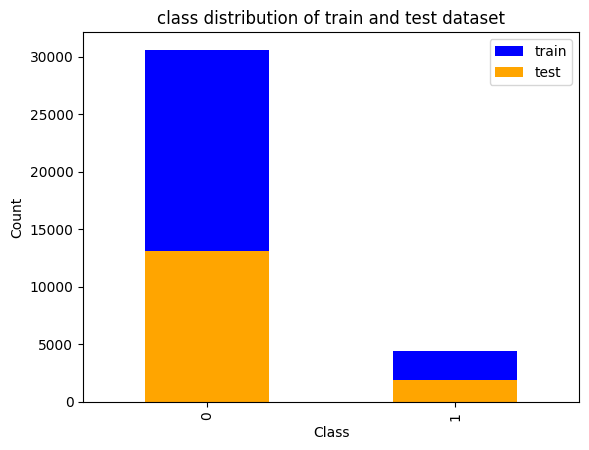

In [25]:
# Plotting target label distribution
plt.figure()
plt.title("class distribution of train and test dataset")
train['label'].value_counts().plot(kind="bar", color='b', label="train")
test['label'].value_counts().plot(kind="bar", color='orange', label="test")
plt.xlabel("Class")
plt.ylabel("Count")
plt.legend()
plt.show()

Both train and test datasets are highly imbalanced.<br>
Percentage of points belongs to class 1 (attack) is very little (only 12.6 %) in both of them.


### Datatype information of the Features

In [26]:
# Check if any null value present in datasets
train.isnull().sum().sum(), test.isnull().sum().sum()  # No Null in train and test data is still raw

(np.int64(19827), np.int64(37575))

In [27]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35000 entries, 6395 to 39593
Data columns (total 49 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   srcip             35000 non-null  object 
 1   sport             35000 non-null  int64  
 2   dstip             35000 non-null  object 
 3   dsport            35000 non-null  object 
 4   proto             35000 non-null  object 
 5   state             35000 non-null  object 
 6   dur               35000 non-null  float64
 7   sbytes            35000 non-null  int64  
 8   dbytes            35000 non-null  int64  
 9   sttl              35000 non-null  int64  
 10  dttl              35000 non-null  int64  
 11  sloss             35000 non-null  int64  
 12  dloss             35000 non-null  int64  
 13  service           35000 non-null  object 
 14  sload             35000 non-null  float64
 15  dload             35000 non-null  float64
 16  spkts             35000 non-null  int64  


In [28]:
# All the datatypes in our dataset
train.dtypes.value_counts()

int64      30
float64    12
object      7
Name: count, dtype: int64

In [29]:
# Categorical feature names
train.select_dtypes(exclude=np.number).columns

Index(['srcip', 'dstip', 'dsport', 'proto', 'state', 'service', 'attack_cat'], dtype='object', name='Name')

In [30]:
# In the research paper it was mentioned that, this is a numerical feature not a categorical
train['ct_ftp_cmd'].unique()

array([nan,  0.,  1.,  6.,  2.,  4.,  5.,  3.,  8.])

In [31]:
train['ct_ftp_cmd']

6395     NaN
44693    NaN
5436     NaN
13840    0.0
1016     0.0
        ... 
33403    NaN
33349    0.0
2169     NaN
48366    0.0
39593    0.0
Name: ct_ftp_cmd, Length: 35000, dtype: float64

In [32]:
mask = (train['is_ftp_login'] == 0) & (train['ct_ftp_cmd'].isna())

print("Missing when is_ftp_login = 0:", mask.sum())

train.loc[mask, 'ct_ftp_cmd'] = 0

print("Remaining missing values:", train['ct_ftp_cmd'].isna().sum())
print(train['ct_ftp_cmd'].value_counts(dropna=False))

Missing when is_ftp_login = 0: 19827
Remaining missing values: 0
ct_ftp_cmd
0.0    34390
1.0      550
2.0       19
4.0       19
3.0       10
5.0        6
6.0        5
8.0        1
Name: count, dtype: int64


In [33]:
train['ct_ftp_cmd'].unique()

array([0., 1., 6., 2., 4., 5., 3., 8.])

In [34]:
# Categorical feature names
train.select_dtypes(exclude=np.number).columns

Index(['srcip', 'dstip', 'dsport', 'proto', 'state', 'service', 'attack_cat'], dtype='object', name='Name')

In [35]:
# Numeric features names
train.select_dtypes(include=np.number).columns

Index(['sport', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss',
       'sload', 'dload', 'spkts', 'dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb',
       'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'sjit', 'djit',
       'stime', 'ltime', 'sintpkt', 'dintpkt', 'tcprtt', 'synack', 'ackdat',
       'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login',
       'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'label'],
      dtype='object', name='Name')

**Observations:**
1. In this dataset there are mainly 2 types of data types present
    - numerical
    - categorical

2. Categorical columns: 'proto', 'service', 'state'

3. From the research paper we found that there are binary columns also-<br>
nummerical but binary: 'is_sm_ips_ports', 'is_ftp_login'

4. Numerical columns : 'id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat',
'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src',
'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm',
'ct_dst_src_ltm', 'ct_ftp_cmd', 'ct_flw_http_mthd',
'ct_src_ltm', 'ct_srv_dst'

5. Target columns: 'attack_cat', 'label'

In [36]:
# Info for test data transformation
saved_dict['binary_col'] = ['is_sm_ips_ports', 'is_ftp_login']

### Fixing values of the columns

In [37]:
# see if binary columns are really binary
for col in 'is_sm_ips_ports', 'is_ftp_login':
    print(train[col].value_counts())
    print()

is_sm_ips_ports
0    34937
1       63
Name: count, dtype: int64

is_ftp_login
0    34390
1      609
2        1
Name: count, dtype: int64



The col "is_ftp_login" has few wrong values like 2, 4. It should only have 0 and 1, If the ftp session is accessed by user and
password then 1 else 0. Need to fix this.

Replacing all the values apart from 0 and 1 from these two columns.

In [38]:
train['is_ftp_login'] = np.where(train['is_ftp_login']>1, 1, train['is_ftp_login'])

In [39]:
train['is_ftp_login'].value_counts()

is_ftp_login
0    34390
1      610
Name: count, dtype: int64

In the feature "service" we have "-" we need to replace that.

In [40]:
train['service'].value_counts()

service
-           17048
dns         10823
http         2884
ftp-data     1741
smtp         1122
ftp           711
ssh           640
pop3           19
snmp            6
dhcp            2
ssl             2
radius          1
irc             1
Name: count, dtype: int64

In [41]:
# removing all the "-" and replacing those with "None"
train['service'] = train['service'].apply(lambda x:"None" if x=="-" else x)

In [42]:
train["service"].nunique()

13

In [43]:
train['service'].value_counts()

service
None        17048
dns         10823
http         2884
ftp-data     1741
smtp         1122
ftp           711
ssh           640
pop3           19
snmp            6
dhcp            2
ssl             2
radius          1
irc             1
Name: count, dtype: int64

In [44]:
# In the research paper there are not 10 unique values
train['attack_cat'].nunique()

11

In [45]:
train['attack_cat'].value_counts()

attack_cat
normal            30578
generic            2977
exploits            598
fuzzers             349
dos                 207
reconnaissance      196
analysis             40
backdoor             26
shellcode            19
backdoors             6
worms                 4
Name: count, dtype: int64

In [46]:
train['attack_cat'] = train['attack_cat'].replace('backdoors','backdoor', regex=True).apply(lambda x: x.strip().lower())

## Saving files to disk

In [47]:
train.shape, test.shape

((35000, 49), (15000, 49))

In [48]:
train.to_csv('../data/train_alldata_EDA.csv', index=False)
test.to_csv('../data/test_alldata_EDA.csv', index=False)

In [49]:
pickle.dump(saved_dict, open('./final_ipynb', 'wb'))

In [50]:
# so it doesnt convert the None value to a None object with is a missing value 
train = pd.read_csv('../data/train_alldata_EDA.csv', keep_default_na=False)

In [51]:
train['service'].value_counts() #- disapeare to nan read as NaN by pandas 

service
None        17048
dns         10823
http         2884
ftp-data     1741
smtp         1122
ftp           711
ssh           640
pop3           19
snmp            6
dhcp            2
ssl             2
radius          1
irc             1
Name: count, dtype: int64

In [52]:
del train 
del test